# QFF 2026 QML Q1: provisional synthetic Phase 1 benchmark

The highest-priority Master Guide specifies a four-qubit VQC and a 200-row, four-feature synthetic benchmark with three informative features. Its literal `make_classification` call fails under the default redundant-feature setting. This notebook uses **`n_redundant=0` as an unconfirmed engineering assumption**. Label 1 is only the synthetic positive-class proxy; there is no clinical validation. The historical fixture and its results are separate.

In [1]:
from pathlib import Path
from IPython.display import Markdown, SVG, display
from src.q1_submission import ROOT, load_existing_or_run
from src.datasets import make_provisional_q1_benchmark
from src.problem import dataset_identity
dataset = make_provisional_q1_benchmark()
print("Dataset:", dataset.generation_parameters)
print("Split:", dataset.X_train.shape, dataset.X_test.shape)
print("Dataset SHA256:", dataset_identity(dataset)["dataset_sha256"])

Dataset: {'n_samples': 200, 'n_features': 4, 'n_informative': 3, 'n_redundant': 0, 'random_state': 42}
Split: (160, 4) (40, 4)
Dataset SHA256: 5e4bebee74b379c199394c99c7deb6ee5418843d0b6380b1f1ef75c7b2bf7b9e


## Reproduce or verify

On a fresh checkout, the next cell runs one bounded 25-evaluation COBYLA training and both Aer benchmarks. When complete saved artifacts are present, it validates and loads them without retraining. The logistic and quantum runs share the deterministic 160/40 split. The model signature includes architecture, parameter order, dataset arrays, split, fitted scaler and package versions.

In [2]:
run = load_existing_or_run()
print("Validated model:", run["manifest"]["model_file"])
print("Convergence evaluations:", len(run["convergence"]))
print("Processor settings:", run["benchmark"]["shared_settings"])

Validated model: results/tables/q1_provisional_vqc_model.json
Convergence evaluations: 25
Processor settings: {'basis_gates': ['rz', 'sx', 'x', 'cx'], 'layout_method': 'sabre', 'noise_model': 'uniform depolarizing on rz/sx/x and cx; symmetric readout bit-flip', 'noise_rates': {'one_qubit_depolarizing': 0.001, 'readout_flip': 0.01, 'two_qubit_depolarizing': 0.005}, 'optimization_level': 1, 'routing_method': 'sabre', 'seed_simulator': 42, 'seed_transpiler': 42, 'shots_per_circuit': 4096}


In [3]:
rows = [("Logistic regression", run["baseline"]["metrics"]), ("Ideal exact VQC", run["ideal"]["metrics"])]
for p in run["benchmark"]["processors"]:
    for mode in ("ideal", "noisy"):
        rows.append((f"{p['name']} {mode} 4096-shot", p[mode]["metrics"]))
lines = ["| Mode | Accuracy | Precision (1) | Recall (1) | F1 (1) | Confusion [0,1] |", "|---|---:|---:|---:|---:|---|"]
for label, m in rows:
    lines.append(f"| {label} | {m['accuracy']:.3f} | {m['precision_label_1']:.3f} | {m['recall_label_1']:.3f} | {m['f1_label_1']:.3f} | `{m['confusion_matrix']}` |")
display(Markdown("## Held-out results\n" + "\n".join(lines)))

## Held-out results
| Mode | Accuracy | Precision (1) | Recall (1) | F1 (1) | Confusion [0,1] |
|---|---:|---:|---:|---:|---|
| Logistic regression | 0.875 | 0.895 | 0.850 | 0.872 | `[[18, 2], [3, 17]]` |
| Ideal exact VQC | 0.600 | 0.700 | 0.350 | 0.467 | `[[17, 3], [13, 7]]` |
| Processor A ideal 4096-shot | 0.600 | 0.700 | 0.350 | 0.467 | `[[17, 3], [13, 7]]` |
| Processor A noisy 4096-shot | 0.550 | 0.625 | 0.250 | 0.357 | `[[17, 3], [15, 5]]` |
| Processor B ideal 4096-shot | 0.625 | 0.727 | 0.400 | 0.516 | `[[17, 3], [12, 8]]` |
| Processor B noisy 4096-shot | 0.600 | 0.700 | 0.350 | 0.467 | `[[17, 3], [13, 7]]` |

In [4]:
import json
ref = run["benchmark"]["unconstrained_circuit_cost"]
swap_diagnostic = json.loads((ROOT / "results" / "tables" / "q1_provisional_swap_diagnostic.json").read_text())
swaps = {p["processor"]: p["verified_inserted_swap_count"] for p in swap_diagnostic["processors"]}
lines = ["| Processor | Gate depth | Measured depth | CX | Verified SWAPs | Gate-depth overhead | CX overhead |", "|---|---:|---:|---:|---:|---:|---:|"]
for p in run["benchmark"]["processors"]:
    c, o = p["circuit_cost"], p["routing_overhead"]
    lines.append(f"| {p['name']} | {c['gate_only_depth']} | {c['full_measured_depth']} | {c['cx_count']} | {swaps[p['name']]} | +{o['gate_only_depth_delta']} | +{o['cx_delta']} |")
display(Markdown("## Circuit costs\nUnconstrained reference: gate depth %s, measured depth %s, CX %s. SWAPs are counted at the SABRE routing stage, before basis decomposition.\n\n%s" % (ref["gate_only_depth"], ref["full_measured_depth"], ref["cx_count"], "\n".join(lines))))

## Circuit costs
Unconstrained reference: gate depth 20, measured depth 21, CX 8. SWAPs are counted at the SABRE routing stage, before basis decomposition.

| Processor | Gate depth | Measured depth | CX | Verified SWAPs | Gate-depth overhead | CX overhead |
|---|---:|---:|---:|---:|---:|---:|
| Processor A | 35 | 36 | 24 | 6 | +15 | +16 |
| Processor B | 20 | 21 | 8 | 0 | +0 | +0 |

## Evidence figures

The plots below are saved experiment outputs generated from the recorded circuits, predictions, coupling maps and optimizer callback. Processor graphs are custom designs permitted by the Master Guide, not hardware calibration maps.

### Judge Model Comparison

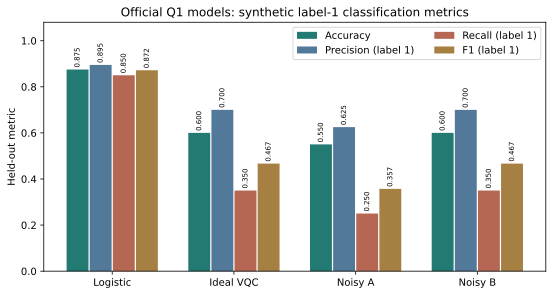

### Confusion Matrices

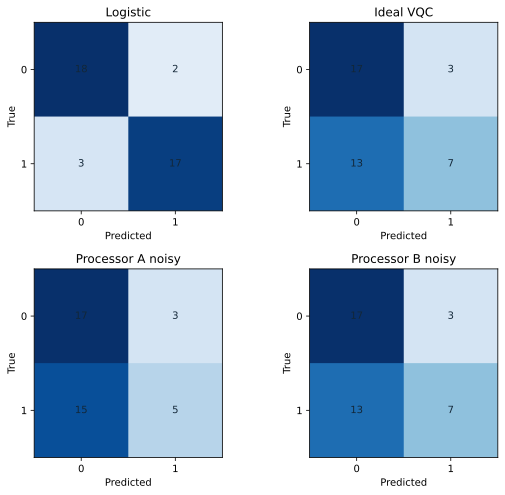

### Circuit Costs

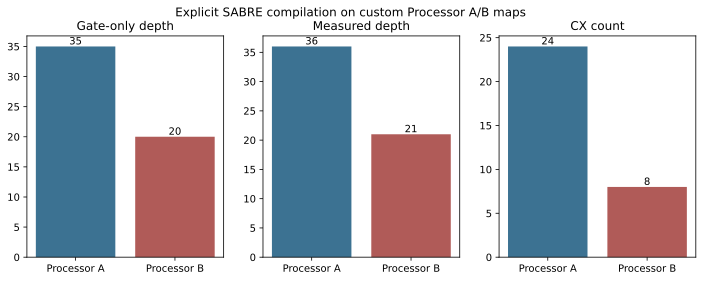

### Training Convergence

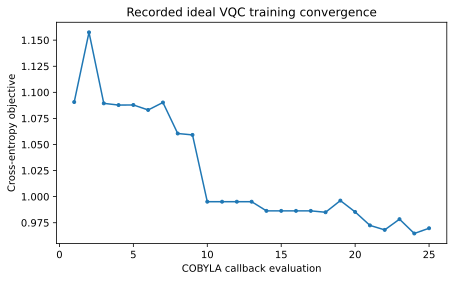

### Processor A Coupling

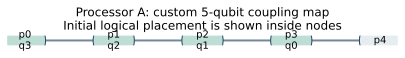

### Processor B Coupling

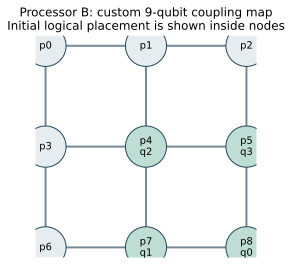

### Logical To Physical Mapping

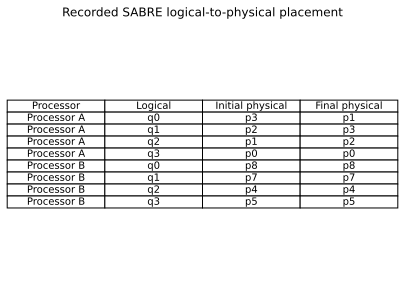

### Logical Circuit

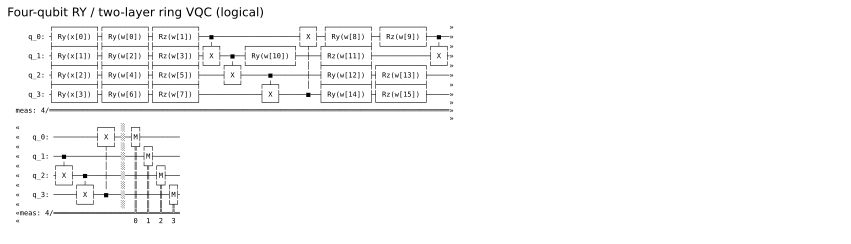

### Processor A Transpiled Circuit

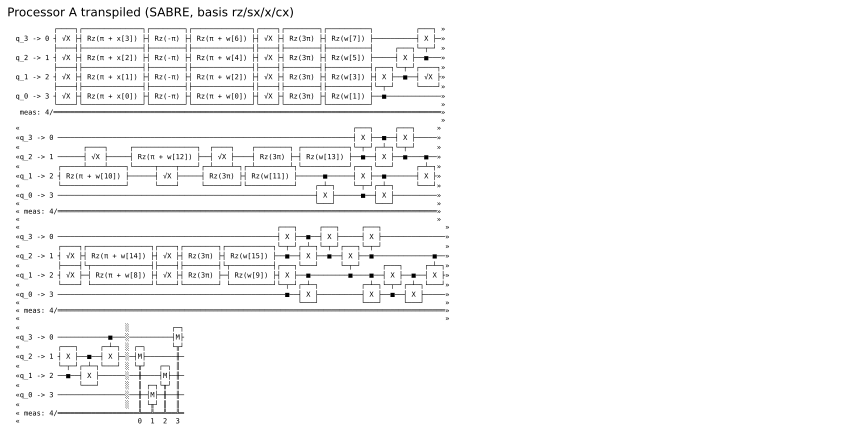

### Processor B Transpiled Circuit

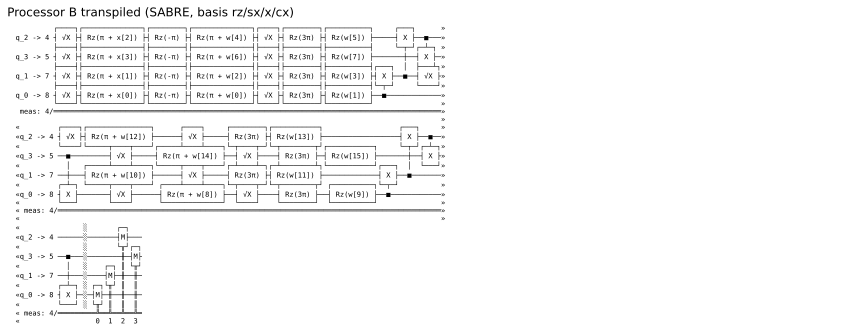

In [5]:
for name in ("judge_model_comparison", "confusion_matrices", "circuit_costs", "training_convergence", "processor_A_coupling", "processor_B_coupling", "logical_to_physical_mapping", "logical_circuit", "processor_A_transpiled_circuit", "processor_B_transpiled_circuit"):
    display(Markdown(f"### {name.replace('_', ' ').title()}"))
    display(SVG(filename=str(ROOT / "results" / "figures" / f"{name}.svg")))

## Judge-facing recall and layout diagnostics

The official full-training VQC stays unchanged. A **separate** 25-evaluation fit uses 128 rows from the original training partition; a stratified 32-row validation partition alone selects a positive-score threshold under precision ≥0.55 and F1 ≥0.60 constraints. Its held-out result is reported once and is not substituted for the official benchmark. The saved score audit independently replays the official exact QNN and checks all original artifact hashes.

The architecture ablation changes only initial layout (`sabre` versus `trivial`); SABRE routing, logical circuit, topology, native basis, level 1 and seed 42 are fixed. It is a transpilation-only cost comparison, not a second processor inference benchmark.

Official exact-score replay maximum error: 0.0
Final-layer RZ score sensitivity: {'w[11]': 0.0, 'w[13]': 0.0, 'w[15]': 0.0, 'w[9]': 0.0}
Original model SHA256: 9902dd5dce0d069633081b7787618f98797fc1442c5ceff5ac3679067c8332fd
Official positive prediction counts:
   logistic_regression 19 confusion [[18, 2], [3, 17]]
   ideal_vqc_exact 10 confusion [[17, 3], [13, 7]]
   Processor A noisy sampled 8 confusion [[17, 3], [15, 5]]
   Processor B noisy sampled 10 confusion [[17, 3], [13, 7]]
Separate experiment: validation rows 32 selected threshold 0.45
Validation metrics: {'accuracy': 0.59375, 'confusion_matrix': [[3, 13], [0, 16]], 'confusion_matrix_labels': [0, 1], 'f1_label_1': 0.7111111111111111, 'precision_label_1': 0.5517241379310345, 'predictions': [1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1], 'recall_label_1': 1.0, 'sample_count': 32}
Held-out metrics: {'accuracy': 0.525, 'confusion_matrix': [[5, 15], [4, 16]], 'confusion_matrix_lab

| Processor | Initial layout | Gate-only depth | CX | Explicit routing-stage SWAPs |
|---|---|---:|---:|---:|
| Processor A | sabre | 35 | 24 | 6 |
| Processor A | trivial | 34 | 22 | 6 |
| Processor B | sabre | 20 | 8 | 0 |
| Processor B | trivial | 26 | 14 | 2 |

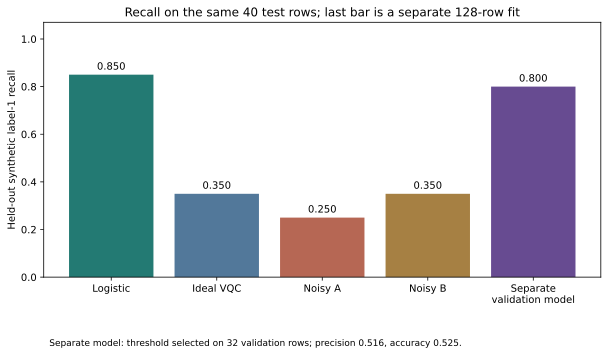

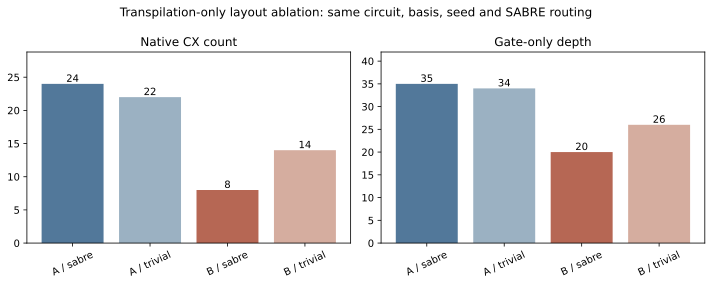

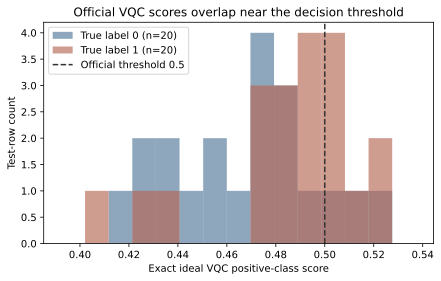

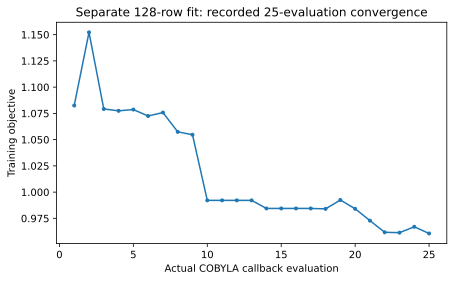

In [6]:
import json
from IPython.display import Markdown, SVG, display
from src.q1_submission import ROOT

audit = json.loads((ROOT / "results/tables/q1_judge_audit.json").read_text())
ablation = json.loads((ROOT / "results/tables/q1_layout_ablation.json").read_text())
calibration = json.loads((ROOT / "results/tables/q1_recall_calibration.json").read_text())

print("Official exact-score replay maximum error:", audit["exact_qnn_score_replay_max_absolute_error"])
print("Final-layer RZ score sensitivity:", audit["final_layer_rz_max_score_changes"])
print("Original model SHA256:", audit["model_file_sha256"])
print("Official positive prediction counts:")
for name in ("logistic_regression", "ideal_vqc_exact", "Processor A noisy sampled", "Processor B noisy sampled"):
    case = audit["cases"][name]
    print("  ", name, case["positive_prediction_count"], "confusion", case["metrics"]["confusion_matrix"])

print("Separate experiment: validation rows", calibration["split"]["validation_rows"],
      "selected threshold", calibration["threshold_search"]["selection"]["threshold"])
print("Validation metrics:", calibration["threshold_search"]["selection"]["validation_metrics"])
print("Held-out metrics:", calibration["held_out_test"]["metrics"])

lines = ["| Processor | Initial layout | Gate-only depth | CX | Explicit routing-stage SWAPs |",
         "|---|---|---:|---:|---:|"]
for row in ablation["rows"]:
    lines.append(f"| {row['processor']} | {row['layout_method']} | {row['cost']['gate_only_depth']} | {row['cost']['cx_count']} | {row['swap_trace_event']['explicit_swap_count']} |")
display(Markdown("\n".join(lines)))
for name in ("recall_analysis", "layout_ablation", "ideal_score_distribution", "recall_calibration_convergence"):
    display(SVG(filename=str(ROOT / "results" / "figures" / f"{name}.svg")))

## Small-sample uncertainty and compiler seeds

These 95% Wilson intervals describe one 40-row synthetic test split (20 positive rows); they do not quantify retraining or clinical variation. Exact paired tests use the same saved examples and are exploratory after inspecting the test set. The three-seed check compiles only; it keeps the seed-42 official result and does not rerun noisy inference.

| Case | Specificity | FP | FN | Recall 95% Wilson interval |
|---|---:|---:|---:|---:|
| Logistic | 0.900 | 2 | 3 | 0.640–0.948 |
| Official ideal VQC | 0.850 | 3 | 13 | 0.181–0.567 |
| Noisy A | 0.850 | 3 | 15 | 0.112–0.469 |
| Noisy B | 0.850 | 3 | 13 | 0.181–0.567 |
| Separate validation model | 0.250 | 15 | 4 | 0.584–0.919 |

Noisy A/B exact paired correctness p: 0.625
Processor A seed 7 CX 24 gate depth 33 routing-stage SWAP 6
Processor A seed 42 CX 24 gate depth 35 routing-stage SWAP 6
Processor A seed 99 CX 24 gate depth 33 routing-stage SWAP 6
Processor B seed 7 CX 8 gate depth 20 routing-stage SWAP 0
Processor B seed 42 CX 8 gate depth 20 routing-stage SWAP 0
Processor B seed 99 CX 8 gate depth 20 routing-stage SWAP 0


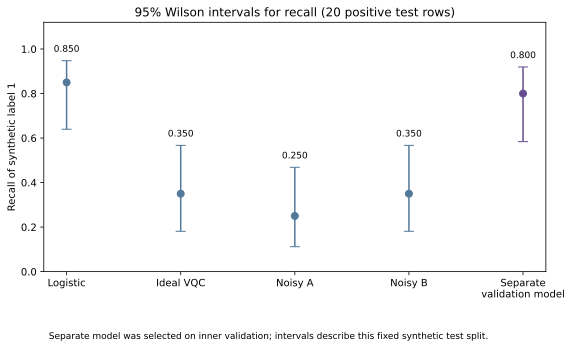

In [7]:
from IPython.display import Markdown, SVG, display
import json
statistics = json.loads((ROOT / "results/tables/q1_statistical_review.json").read_text())
robustness = json.loads((ROOT / "results/tables/q1_seed_robustness.json").read_text())
lines = ["| Case | Specificity | FP | FN | Recall 95% Wilson interval |", "|---|---:|---:|---:|---:|"]
for key, title in (("logistic", "Logistic"), ("ideal_vqc", "Official ideal VQC"), ("processor_A_noisy", "Noisy A"), ("processor_B_noisy", "Noisy B"), ("separate_validation_model", "Separate validation model")):
    case = statistics["cases"][key]
    interval = case["wilson_95_percent"]["recall_label_1"]
    lines.append(f"| {title} | {case['specificity_label_0']:.3f} | {case['false_positives']} | {case['false_negatives']} | {interval[0]:.3f}–{interval[1]:.3f} |")
display(Markdown("\n".join(lines)))
print("Noisy A/B exact paired correctness p:", statistics["paired_comparisons"]["processor_A_noisy_vs_processor_B_noisy"]["exact_two_sided_mcnemar_accuracy_p"])
for row in robustness["rows"]:
    print(row["processor"], "seed", row["seed_transpiler"], "CX", row["cx_count"], "gate depth", row["gate_only_depth"], "routing-stage SWAP", row["explicit_swap_count_after_sabre_layout"])
display(SVG(filename=str(ROOT / "results/figures/recall_uncertainty.svg")))

## Five-category evidence and conceptual Processor D

The team reports organizer confirmation of the category weights below and 70% LLM / 30% human split. The local Master Guide PDF contains an earlier four-category rubric; the updated announcement file itself is not in the local organizer PDF directory.

| Review category | Points | Direct evidence |
|---|---:|---|
| Technical Correctness | 30 | `src/vqc.py`, `tests/test_circuit_semantics.py`, `results/tables/q1_provisional_manifest.json` |
| Processor A/B Benchmarking | 25 | `results/tables/q1_provisional_processor_benchmark.json`, `results/tables/q1_provisional_swap_diagnostic.json` |
| Performance Analysis | 20 | `results/tables/q1_statistical_review.json`, `results/figures/confusion_matrices.svg` |
| Code Quality & Reproducibility | 15 | `requirements.txt`, `docs/FINAL_VERIFICATION.md` |
| Technical Explanation | 10 | `report.md`, `docs/JUDGE_SUMMARY.md`, `docs/PROCESSOR_D_CONCEPT.md` |

The diagram below places the four logical qubits on the **recorded** A/B layouts. Its D panel is a proposed five-qubit ring-compatible topology, **not** a compiled or benchmarked Processor D. The latest local Master Guide reserves D execution for Phase 2. The Qiskit-generated logical and transpiled circuit drawings above, rather than this topology schematic, document the exact gates.

The circuit semantics test identifies the six output-inert trainable parameters as `w[9]`, `w[10]`, `w[11]`, `w[13]`, `w[14]`, and `w[15]`: final-layer RZ on all qubits and RY on q1/q3. The final CX ring makes odd-parity readout equal pre-ring q0 XOR q2. `tests/test_circuit_semantics.py` verifies the parity identity for all 16 basis outcomes and checks parameter perturbations against the measured class probabilities.

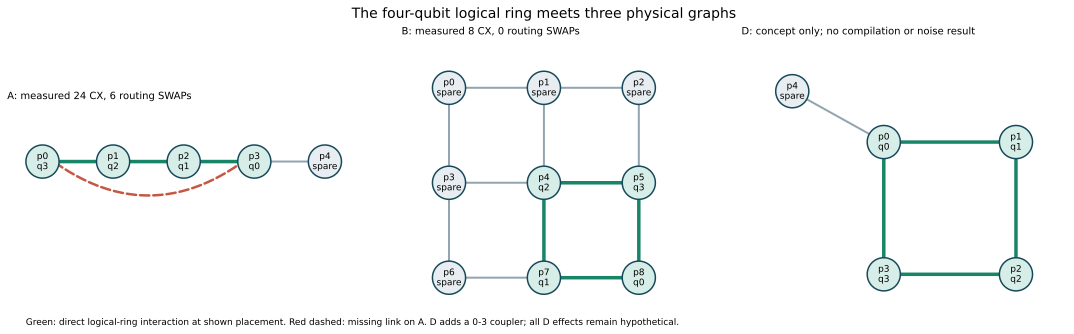

In [8]:
display(SVG(filename=str(ROOT / "results/figures/architecture_problem_and_D_concept.svg")))

## Limits and provenance

The prescribed noise probabilities are synthetic assumptions: one-qubit depolarizing 0.001, CX depolarizing 0.005, symmetric readout 0.01; 4,096 shots, level-1 optimization, SABRE layout and routing, and transpilation seed 42. Both processor runs use the same saved weights and test rows. The test set did not drive architecture selection. This small synthetic experiment shows no quantum advantage or clinical validity. See `report.md`, `docs/DECISIONS.md`, and `results/tables/q1_provisional_manifest.json` for details.

The synthetic positive class is not a clinically validated abnormal ECG diagnosis. The provisional `n_redundant=0` generator correction remains an unconfirmed engineering assumption.